In [1]:
import mindmap as mm
import mne
from pathlib import Path
import numpy as np

import pyxu.abc as pxa

In [44]:
sub = "sub-pat10"

# configuration 
config = mm.io.read_config("../configurations/spike.yml")
mm_dir = Path(config["MM_DIR"])

# files
fwd = mm_dir/sub/"fwd"/f"{sub}_bem-fwd.fif"
cst = mm_dir/sub/"cst"/f"{sub}_cst-template.npy"
eeg = mm_dir/sub/"eeg"/f"{sub}_coreg_ave.fif"

# data
fwd = mne.read_forward_solution(fwd, verbose="warning")
cst = np.load(cst, allow_pickle=True)
eeg = mne.read_evokeds(eeg, verbose="warning")[0]

# fix orientations
fwd = mne.convert_forward_solution(
    fwd,
    surf_ori=True,
    force_fixed=True,
    use_cps=True,
    verbose="warning",
)

# operators
A = pxa.LinOp.from_array(fwd["sol"]["data"])
F = pxa.LinOp.from_array(cst)

In [45]:
# exponential probability distribution
param = 0.01
p = param*np.exp(-param*np.arange(cst.shape[0]))
p = p/p.sum()

# select harmonics and values
n         = 100
harmonics = np.random.choice(range(cst.shape[0]), n, replace=False, p=p)
values    = np.random.randint(-10, 10, n)

# create connectome spectrum
alpha = np.zeros(cst.shape[0])
alpha[harmonics] = values*10**-9

# create signal
original = F.adjoint(alpha)

mm.viz.plot_brain_signal(fwd["src"], original, clim=[-np.abs(original).max(), np.abs(original).max()]).show()

Widget(value='<iframe src="http://localhost:46139/index.html?ui=P_0x7f5b8db767e0_8&reconnect=auto" class="pyvi…

/home/nino/miniconda3/envs/mindmap/lib/python3.12/site-packages/pyxu/operator/linop/base.py:482: PrecisionWarning: Computation may not be performed at the requested precision.
  warnings.warn(msg, pxw.PrecisionWarning)


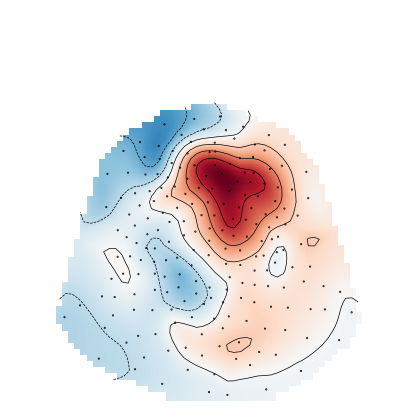

In [41]:
# project to electrodes 
A   = pxa.LinOp.from_array(fwd["sol"]["data"])
sim = A(original)
_ = mne.viz.plot_topomap(sim, eeg.info, outlines=None, extrapolate="local", size=4)

In [53]:
import pyxu.operator as pxo

Reg = pxo.L1Norm(dim_shape=F.dim_shape) * F

Reg.prox()

AttributeError: 'Func' object has no attribute 'prox'

In [5]:
import h5py 
import matplotlib.pyplot as plt 

f = h5py.File("/home/nino/Downloads/LinkAndShare_TimeSeriesRegion.h5", "r")

f.keys()

<KeysViewHDF5 ['data', 'time']>

Text(0.5, 1.0, 'Regions TemporalAverage')

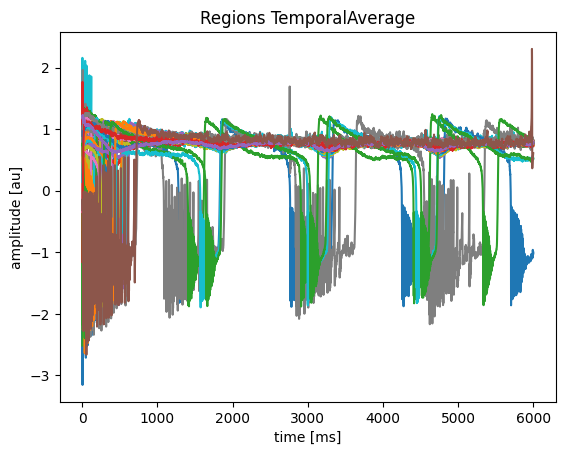

In [22]:
plt.plot(f["time"][:], f["data"][:,0,:,0])
plt.xlabel("time [ms]")
plt.ylabel("amplitude [au]")
plt.title(f.attrs["TVB_title"])
